# Entropy vs Gini Impurity | Information Gain | Pruning and Overfitting

In [13]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
# entropy manually
spam = 40
ham = 10
total = spam + ham

p_spam = spam / total
p_ham = ham / total

entropy = -(p_spam*np.log2(p_spam) + p_ham*np.log2(p_ham))
print(f"Entropy: {entropy:.4f}")

Entropy: 0.7219


In [ ]:
# Gini Impurity and Entropy

def gini(proportions):
    # 1 - (p1^2 + p2^2 + ... + pn^2) for 2 classes, from 0.0 to 0.5
    return 1 - sum(p**2 for p in proportions)

def entropy(proportions):
    # - (p1*log2(p1) + p2*log2(p2) + ... + pn*log2(pn)) for 2 classes, from 0.0 to 1.0
    # p=0 log2(0) --> infinity
    return -sum(p*np.log2(p) for p in proportions if p > 0)


conditions = [
    ("Pure(100/0)", [1.0, 0.0]),
    ("90/10", [0.9, 0.1]),
    ("80/20", [0.8, 0.2]),
    ("70/30", [0.7, 0.3]),
    ("60/40", [0.6, 0.4]),
    ("Impure(50/50)", [0.5, 0.5]),
]

print(f"{'Condition':<15} {'Gini':<10} {'Entropy':<10}")
print("-" * 35)
for name, proportions in conditions:
    gini_value = gini(proportions)
    entropy_value = entropy(proportions)
    print(f"{name:<15} {gini_value:<10.4f} {entropy_value:<10.4f}")

Condition       Gini       Entropy   
-----------------------------------
Pure(100/0)     0.0000     -0.0000   
90/10           0.1800     0.4690    
80/20           0.3200     0.7219    
70/30           0.4200     0.8813    
60/40           0.4800     0.9710    
Impure(50/50)   0.5000     1.0000    


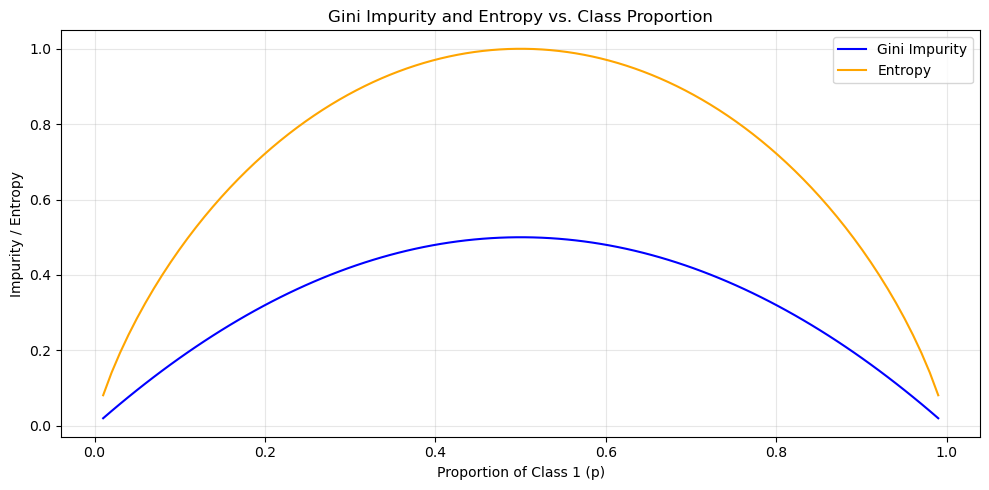

In [ ]:
# Gini Impurity and Entropy in Graph
p_values = np.linspace(0.01, 0.99, 100)
gini_values = [gini([p, 1-p]) for p in p_values]
entropy_values = [entropy([p, 1-p]) for p in p_values]

plt.figure(figsize=(10, 5))
plt.plot(p_values, gini_values, label='Gini Impurity', color='blue')
plt.plot(p_values, entropy_values, label='Entropy', color='orange')
plt.xlabel('Proportion of Class 1 (p)')
plt.ylabel('Impurity / Entropy')
plt.title('Gini Impurity and Entropy vs. Class Proportion')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
## Information Gain
H_father = entropy([30/60, 30/60])  # Entropy of the parent node (50/50)

# question: salary > 50k
H_left = entropy([5/30, 25/30])  # Entropy of the left child node (90/10)
H_right = entropy([25/30, 5/30])  # Entropy of the right child node (10/90)

# weighted average of the child nodes
H_weighted = (30/60) * H_left + (30/60) * H_right

# information gain
IG = H_father - H_weighted
print(f"Information Gain: {IG:.4f}")
print("Tree choses the feature with the highest information gain to split the data at each node.")

Information Gain: 0.3500
Tree choses the feature with the highest information gain to split the data at each node.


In [21]:
# Overfitting and Pruning
# Pruning is like trimming a tree to remove branches 

from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

data = load_wine()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# different max_depth values to see the effect of overfitting(Pruning)
for max_depth in [1, 2, 3, 4, 5, 10, None]:
    clf = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    clf.fit(X_train, y_train)
    train_score = clf.score(X_train, y_train)
    test_score = clf.score(X_test, y_test)
    print(f"Max Depth: {max_depth}, Train Score: {train_score:.4f}, Test Score: {test_score:.4f}, Overfitting: {train_score - test_score:.4f}")

Max Depth: 1, Train Score: 0.6408, Test Score: 0.6667, Overfitting: -0.0258
Max Depth: 2, Train Score: 0.9366, Test Score: 0.8611, Overfitting: 0.0755
Max Depth: 3, Train Score: 0.9930, Test Score: 0.9444, Overfitting: 0.0485
Max Depth: 4, Train Score: 1.0000, Test Score: 0.9444, Overfitting: 0.0556
Max Depth: 5, Train Score: 1.0000, Test Score: 0.9444, Overfitting: 0.0556
Max Depth: 10, Train Score: 1.0000, Test Score: 0.9444, Overfitting: 0.0556
Max Depth: None, Train Score: 1.0000, Test Score: 0.9444, Overfitting: 0.0556
